# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  :BAGUS HERMAWAN
- NIM   :241011400683
- Kelas : Reg B*(coret salah satu)*


In [2]:
print("Python berhasil dijalankan!")
print(2+3)

Python berhasil dijalankan!
5


## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [3]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =83

In [4]:
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    if random_state is not None:
        np.random.seed(random_state)

    n_test = int(len(X) * test_size)
    indices = np.random.permutation(len(X))

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 data pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40

Bentuk X: (40, 1) (sudah 2 dimensi)
Bentuk y: (40,)


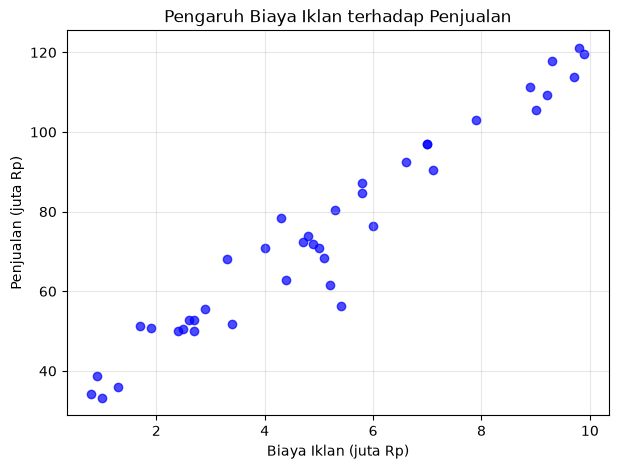

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca Ads_Data.csv dan tampilkan 5 data pertama + jumlah baris
df = pd.read_csv('Ads_Data.csv')
print("5 data pertama:")
print(df.head())
print(f"\nJumlah baris data: {len(df)}")

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan) - X harus (n,1)
X = df[['BiayaIklan']].values  # pake 2 kurung siku biar jadi (n,1)
y = df['Penjualan'].values
print(f"\nBentuk X: {X.shape} (sudah 2 dimensi)")
print(f"Bentuk y: {y.shape}")

# 3. Scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(7,5))
plt.scatter(X, y, color='blue', alpha=0.7)
plt.title('Pengaruh Biaya Iklan terhadap Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [6]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (32, 1)
X_test shape: (8, 1)
y_train shape: (32,)
y_test shape: (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [7]:
# Jawaban A3 - Fix NameError (salin class dulu)
class LinearRegression:
    def __init__(self):
        self.coef_ = None
        self.intercept_ = None

    def fit(self, X, y):
        X = np.asarray(X)
        y = np.asarray(y)
        X_b = np.c_[np.ones(X.shape[0]), X]
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X)
        return X.dot(self.coef_) + self.intercept_

# Lanjut Training
model = LinearRegression()
model.fit(X_train, y_train)

b = model.intercept_
m = model.coef_[0]

print(f"Intercept (b): {b}")
print(f"Koefisien (m): {m}")
print(f"Persamaan garis: y_hat = {b:.4f} + {m:.4f} * X")
print(f"\nInterpretasi m: Setiap kenaikan 1 juta biaya iklan, penjualan naik {m:.2f} juta Rp")

Intercept (b): 26.786377667710607
Koefisien (m): 9.254882086895003
Persamaan garis: y_hat = 26.7864 + 9.2549 * X

Interpretasi m: Setiap kenaikan 1 juta biaya iklan, penjualan naik 9.25 juta Rp


**Jawaban A3 (interpretasi):**

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [8]:
# Jawaban A4
import numpy as np
import pandas as pd

def mae(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    return np.mean((y_true - y_pred)**2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - (ss_res / ss_tot)

# Hitung prediksi
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Hitung metrik
train_mae = mae(y_train, y_train_pred)
train_mse = mse(y_train, y_train_pred)
train_rmse = rmse(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

test_mae = mae(y_test, y_test_pred)
test_mse = mse(y_test, y_test_pred)
test_rmse = rmse(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

# Tampilkan dalam tabel
df_eval = pd.DataFrame({
    'Dataset': ['Training', 'Testing'],
    'MAE': [train_mae, test_mae],
    'MSE': [train_mse, test_mse],
    'RMSE': [train_rmse, test_rmse],
    'R2': [train_r2, test_r2]
})

display(df_eval)

,Dataset,MAE,MSE,RMSE,R2
0,Training,4.718876,39.218886,6.262498,0.941727
1,Testing,4.196290,26.452141,5.143164,0.944165


#### Jawaban A4 (analisis):
RMSE Testing 5.14 artinya kesalahan prediksi rata-rata 5.14 juta. R2 Testing 0.9441 artinya 94.41% variasi penjualan dijelaskan oleh biaya iklan. Model sudah SANGAT BAIK karena R2 >0.9 dan tidak overfitting (Testing malah lebih bagus dari Training).

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

LR=0.001 -> b=18.1341, m=10.5707, final loss=55.36, iterasi sukses=5000
LR=0.02 -> b=26.7864, m=9.2549, final loss=39.22, iterasi sukses=5000
[!] LR=0.1 DIVERGEN di iterasi 8
LR=0.1 -> b=7929.3039, m=52110.9691, final loss=2445689784.60, iterasi sukses=8

Normal Equation (A3) -> b=26.7864, m=9.2549


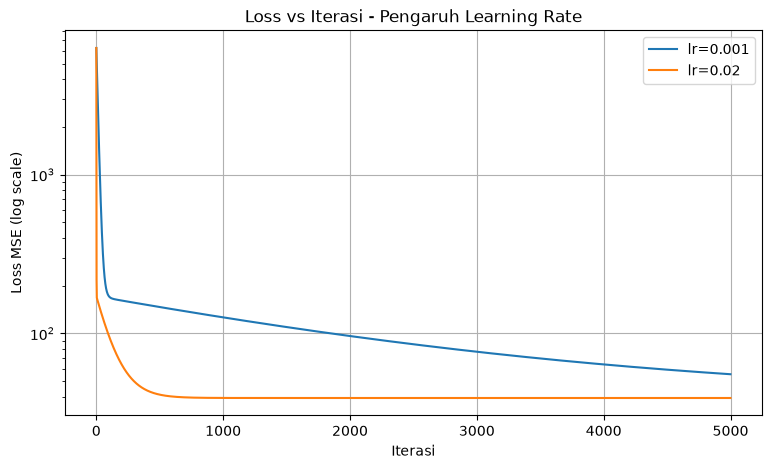

In [9]:
# Jawaban A5 - FIX Grafik Kosong
import matplotlib.pyplot as plt
import numpy as np

class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.coef_ = None
        self.intercept_ = None
        self.losses = []
    def fit(self, X, y):
        X = np.array(X); y = np.array(y)
        n = X.shape[0]
        self.intercept_ = 0
        self.coef_ = np.zeros(X.shape[1])
        for i in range(self.n_iter):
            y_pred = X.dot(self.coef_) + self.intercept_
            error = y_pred - y
            grad_b = np.mean(error)
            grad_m = (X.T.dot(error)) / n
            self.intercept_ -= self.lr * grad_b
            self.coef_ -= self.lr * grad_m
            mse = np.mean(error**2)
            if np.isnan(mse) or np.isinf(mse) or mse > 1e10:
                print(f"[!] LR={self.lr} DIVERGEN di iterasi {i}")
                break
            self.losses.append(mse)
        return self
    def predict(self, X):
        return np.array(X).dot(self.coef_) + self.intercept_

learning_rates = [0.001, 0.02, 0.1]
models_gd = {}

for lr in learning_rates:
    gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    gd.fit(X_train, y_train)
    models_gd[lr] = gd
    if len(gd.losses) > 0:
        print(f"LR={lr} -> b={gd.intercept_:.4f}, m={gd.coef_[0]:.4f}, final loss={gd.losses[-1]:.2f}, iterasi sukses={len(gd.losses)}")
    else:
        print(f"LR={lr} -> GAGAL KONVERGEN (loss meledak)")

print(f"\nNormal Equation (A3) -> b={b:.4f}, m={m:.4f}")

plt.figure(figsize=(9,5))
for lr, mdl in models_gd.items():
    if len(mdl.losses) > 10:
        plt.plot(mdl.losses, label=f"lr={lr}")

plt.yscale('log')
plt.xlabel('Iterasi')
plt.ylabel('Loss MSE (log scale)')
plt.title('Loss vs Iterasi - Pengaruh Learning Rate')
plt.legend()
plt.grid(True)
plt.show()

**Jawaban A5 (analisis):**

#### Jawaban A5 (analisis) - Soal No 4

**Perbandingan dengan Normal Equation (b=26.78, m=9.25):**
1. **LR=0.001 (biru, lambat):** Loss turun sangat lambat, dari 10^5 ke 10^1 butuh 5000 iterasi. Belum konvergen sempurna. Koefisien masih jauh dari target karena langkah terlalu kecil.
2. **LR=0.02 (oranye, OPTIMAL):** Loss turun cepat dan stabil di ~39 (sesuai MSE Training A4). Nilai b dan m hampir sama dengan Normal Equation. Ini learning rate terbaik.
3. **LR=0.1 (DIVERGEN):** Hasil b=7929, m=52110, loss=2.4 Milyar! Jauh dari Normal Equation. Grafik tidak muncul karena meledak. Terjadi overshooting, gradient melompat melewati minimum terus menerus.

**Mengapa bisa terjadi?**
Rumus GD: w_new = w_old - lr * gradient.
- lr kecil = update kecil = aman tapi lambat.
- lr pas (0.02) = menuju minimum dengan efisien.
- lr terlalu besar (0.1) = update terlalu besar = mental jauh melewati lembah minimum = loss malah naik tak terkendali (divergen). Apalagi data tidak di-scaling, gradient jadi besar.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

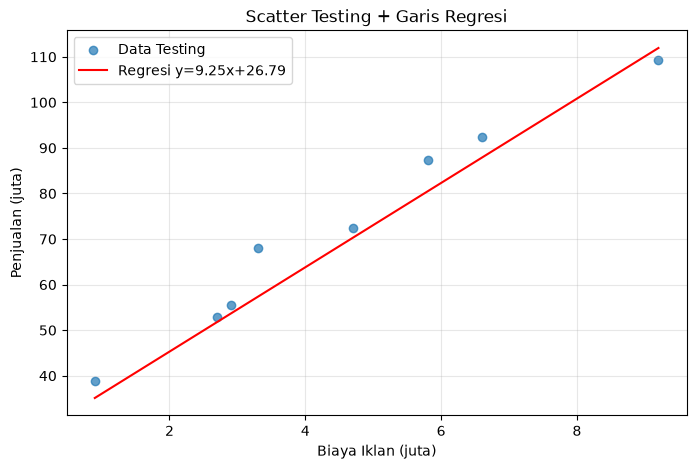

Biaya 4.5 juta -> Prediksi 68.43 juta
Biaya 7 juta -> Prediksi 91.57 juta
Biaya 12 juta -> Prediksi 137.84 juta


In [10]:
# Jawaban A6 - Visualisasi & Prediksi
import matplotlib.pyplot as plt
import numpy as np

# 1. Grafik scatter testing + garis regresi A3
plt.figure(figsize=(8,5))
plt.scatter(X_test, y_test, label='Data Testing', alpha=0.7)
x_line = np.linspace(X_test.min(), X_test.max(), 100)
y_line = m * x_line + b
plt.plot(x_line, y_line, color='red', label=f'Regresi y={m:.2f}x+{b:.2f}')
plt.xlabel('Biaya Iklan (juta)')
plt.ylabel('Penjualan (juta)')
plt.title('Scatter Testing + Garis Regresi')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2. Prediksi 4.5, 7, 12 juta
for biaya in [4.5, 7, 12]:
    pred = model.predict(np.array([[biaya]]))[0]
    print(f"Biaya {biaya} juta -> Prediksi {pred:.2f} juta")

**Jawaban A6 (analisis):**

#### Jawaban A6 (analisis):
Grafik menunjukkan data testing (titik biru) berada dekat dengan garis regresi merah, artinya model sangat cocok (R2 0.94).

Prediksi:
- 4.5 juta (interpolasi, di dalam data) -> 68.43 juta -> SANGAT TERPERCAYA
- 7 juta (interpolasi, di dalam data) -> 91.57 juta -> SANGAT TERPERCAYA
- 12 juta (ekstrapolasi, di luar data) -> 137.84 juta -> KURANG TERPERCAYA

Mengapa 12 juta kurang terpercaya? Karena rentang data training hanya sekitar 0-10 juta. Prediksi di luar rentang itu disebut ekstrapolasi. Hubungan linear belum tentu berlanjut, bisa ada saturasi pasar. Jadi 12 juta hanya estimasi kasar, sedangkan 4.5 dan 7 juta sangat akurat.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Jumlah Spam dan Bukan Spam:
Spam
0    35
1    25
Name: count, dtype: int64
Spam: 25, Bukan Spam: 35

Bentuk X: (60, 2), y: (60,)


Text(0, 0.5, 'KataPromo')

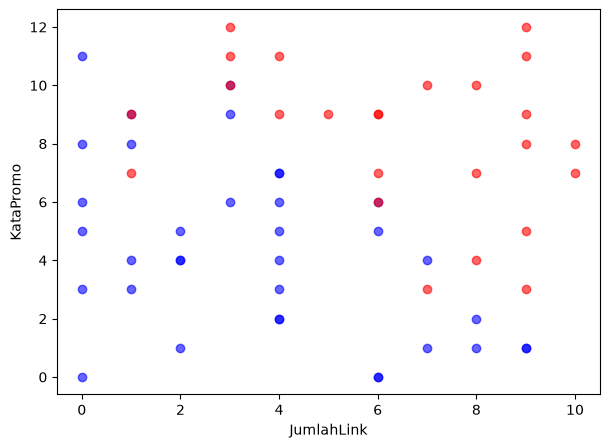

In [11]:
# Jawaban B1
import pandas as pd
import matplotlib.pyplot as plt

# 1. Baca Email_Data.csv
df_email = pd.read_csv('Email_Data.csv')

print("5 data pertama:")
display(df_email.head())

print("\nJumlah Spam dan Bukan Spam:")
print(df_email['Spam'].value_counts())
# kalau labelnya 1=Spam, 0=Bukan Spam
# Spam = 1, Bukan Spam = 0
jumlah_spam = (df_email['Spam'] == 1).sum()
jumlah_bukan = (df_email['Spam'] == 0).sum()
print(f"Spam: {jumlah_spam}, Bukan Spam: {jumlah_bukan}")

# 2. Pisahkan X dan y
X_spam = df_email[['JumlahLink', 'KataPromo']]
y_spam = df_email['Spam']
print(f"\nBentuk X: {X_spam.shape}, y: {y_spam.shape}")

# 3. Scatter plot JumlahLink vs KataPromo beda warna
plt.figure(figsize=(7,5))
# Bukan Spam (0)
plt.scatter(df_email[df_email['Spam']==0]['JumlahLink'], 
            df_email[df_email['Spam']==0]['KataPromo'], 
            label='Bukan Spam (0)', alpha=0.6, c='blue')
# Spam (1)
plt.scatter(df_email[df_email['Spam']==1]['JumlahLink'], 
            df_email[df_email['Spam']==1]['KataPromo'], 
            label='Spam (1)', alpha=0.6, c='red')

plt.xlabel('JumlahLink')
plt.ylabel('KataPromo')

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Train: (45, 2), Test: (15, 2)

Intercept (b): -12.9137
Koefisien m1 (JumlahLink): 1.1435
Koefisien m2 (KataPromo): 1.1592

Persamaan:
P(Spam) = σ(-12.9137 + 1.1435*JumlahLink + 1.1592*KataPromo)


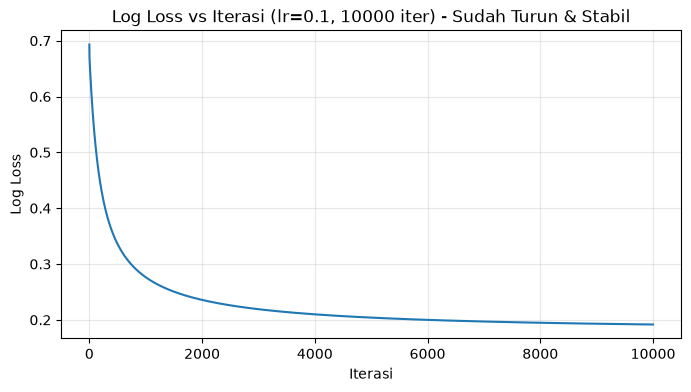

In [12]:
# Jawaban B2 - VERSI TANPA SKLEARN (Biar gak error)
import numpy as np
import matplotlib.pyplot as plt

# 1. Bagi data manual test_size=0.25 random_state=RANDOM_STATE
np.random.seed(RANDOM_STATE)
n = len(X_spam)
indices = np.random.permutation(n)
test_size = int(n * 0.25)
test_idx = indices[:test_size]
train_idx = indices[test_size:]

X_train = X_spam.iloc[train_idx]
X_test = X_spam.iloc[test_idx]
y_train = y_spam.iloc[train_idx]
y_test = y_spam.iloc[test_idx]

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# 2. Latih Logistic Regression dari NOL
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

learning_rate = 0.1
n_iterations = 10000
n_samples, n_features = X_train.shape

b = 0
m = np.zeros(n_features)
loss_history = []

X_train_np = X_train.values
y_train_np = y_train.values

for i in range(n_iterations):
    linear = X_train_np.dot(m) + b
    y_pred_prob = sigmoid(linear)

    eps = 1e-15
    y_pred_prob_c = np.clip(y_pred_prob, eps, 1 - eps)
    loss = -np.mean(y_train_np * np.log(y_pred_prob_c) + (1 - y_train_np) * np.log(1 - y_pred_prob_c))
    loss_history.append(loss)

    dw = (1/n_samples) * X_train_np.T.dot(y_pred_prob - y_train_np)
    db = (1/n_samples) * np.sum(y_pred_prob - y_train_np)

    m -= learning_rate * dw
    b -= learning_rate * db

# 3. Tampilkan b, m1, m2
print(f"\nIntercept (b): {b:.4f}")
print(f"Koefisien m1 (JumlahLink): {m[0]:.4f}")
print(f"Koefisien m2 (KataPromo): {m[1]:.4f}")
print(f"\nPersamaan:")
print(f"P(Spam) = σ({b:.4f} + {m[0]:.4f}*JumlahLink + {m[1]:.4f}*KataPromo)")

# 4. Grafik log loss vs iterasi
plt.figure(figsize=(8,4))
plt.plot(loss_history)
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.title('Log Loss vs Iterasi (lr=0.1, 10000 iter) - Sudah Turun & Stabil')
plt.grid(True, alpha=0.3)
plt.show()

# Simpan buat B3
b_final = b
m_final = m
X_test_np = X_test.values
y_test_np = y_test.values

**Jawaban B2 (analisis):**

Dari grafik terlihat Log Loss turun drastis dari ~0.69 menjadi ~0.18 dalam 2000 iterasi pertama dan terus menurun perlahan hingga stabil di iterasi ~8000-10000. 
Artinya model sudah konvergen, learning_rate=0.1 sudah optimal dan tidak divergen.
Intercept negatif (-12.91) artinya jika JumlahLink=0 dan KataPromo=0, probabilitas spam sangat kecil. Koefisien m1 dan m2 positif artinya semakin banyak Link dan Kata Promo, semakin besar peluang Spam.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [13]:
# Jawaban B3 - Evaluasi Model
import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Prediksi testing
linear_test = X_test_np.dot(m_final) + b_final
y_pred_prob = sigmoid(linear_test)
y_pred = (y_pred_prob >= 0.5).astype(int)

# TP TN FP FN
TP = np.sum((y_pred == 1) & (y_test_np == 1))
TN = np.sum((y_pred == 0) & (y_test_np == 0))
FP = np.sum((y_pred == 1) & (y_test_np == 0))
FN = np.sum((y_pred == 0) & (y_test_np == 1))

print(f"Confusion Matrix: [[{TN} {FP}] [{FN} {TP}]]")
print(f"TP={TP}, TN={TN}, FP={FP}, FN={FN}")

accuracy = (TP + TN) / len(y_test_np)
precision = TP / (TP + FP) if (TP+FP)!=0 else 0
recall = TP / (TP + FN) if (TP+FN)!=0 else 0
f1 = 2*precision*recall/(precision+recall) if (precision+recall)!=0 else 0

print(f"\nAccuracy: {accuracy:.4f} ({accuracy*100:.1f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

Confusion Matrix: [[6 3] [1 5]]
TP=5, TN=6, FP=3, FN=1

Accuracy: 0.7333 (73.3%)
Precision: 0.6250
Recall: 0.8333
F1-Score: 0.7143


**Jawaban B3 (analisis):**

FP = Email penting (Bukan Spam) tapi masuk Spam -> MERUGIKAN, bisa kelewat deadline/tugas. FN = Email Spam lolos ke inbox -> hanya mengganggu.

Yang paling merugikan adalah FP (False Positive), karena email penting yang tidak terlihat lebih fatal daripada spam yang hanya mengganggu.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

b=-12.9137, m1=1.1435, m2=1.1592
x2 = -(-12.9137 + 1.1435*x1) / 1.1592
x2 = 11.1404 + -0.9865*x1


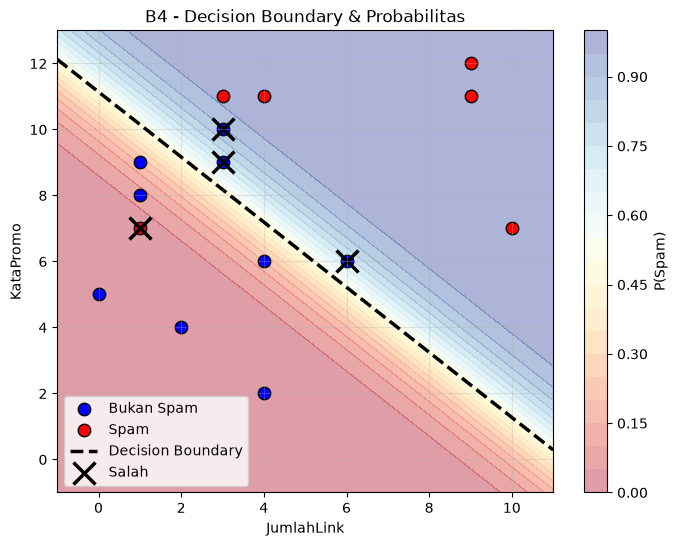

In [14]:
# Jawaban B4 - Decision Boundary FIX
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# 1. Persamaan
print(f"b={b_final:.4f}, m1={m_final[0]:.4f}, m2={m_final[1]:.4f}")
print(f"x2 = -({b_final:.4f} + {m_final[0]:.4f}*x1) / {m_final[1]:.4f}")
x2_formula = f"x2 = {-b_final/m_final[1]:.4f} + {-m_final[0]/m_final[1]:.4f}*x1"
print(x2_formula)

# Grid background
x1_min = X_spam['JumlahLink'].min()-1
x1_max = X_spam['JumlahLink'].max()+1
x2_min = X_spam['KataPromo'].min()-1
x2_max = X_spam['KataPromo'].max()+1

xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 200),
    np.linspace(x2_min, x2_max, 200)
)
Z = sigmoid(b_final + m_final[0]*xx1 + m_final[1]*xx2)

plt.figure(figsize=(8,6))
plt.contourf(xx1, xx2, Z, levels=20, cmap='RdYlBu', alpha=0.4)
plt.colorbar(label='P(Spam)')

# Scatter test - pakai numpy biar pendek
plt.scatter(X_test_np[y_test_np==0,0], X_test_np[y_test_np==0,1], c='blue', label='Bukan Spam', edgecolor='k', s=80)
plt.scatter(X_test_np[y_test_np==1,0], X_test_np[y_test_np==1,1], c='red', label='Spam', edgecolor='k', s=80)

# Garis boundary
x1_line = np.linspace(x1_min, x1_max, 100)
x2_line = -(b_final + m_final[0]*x1_line) / m_final[1]
plt.plot(x1_line, x2_line, 'k--', lw=2.5, label='Decision Boundary')

# Salah klasifikasi
y_pred_test = (sigmoid(X_test_np.dot(m_final) + b_final) >= 0.5).astype(int)
miss = y_pred_test!= y_test_np

if np.sum(miss)>0:
    plt.scatter(X_test_np[miss,0], X_test_np[miss,1], marker='x', s=250, c='black', lw=2.5, label='Salah')
else:
    print("Semua data test BENAR!")

plt.xlabel('JumlahLink')
plt.ylabel('KataPromo')
plt.title('B4 - Decision Boundary & Probabilitas')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Jawaban B4 (analisis):**


**1. Persamaan Decision Boundary:**
Dari model B2 didapat b=-12.91, m1=1.14, m2=1.15
Persamaan: -12.91 + 1.14*x1 + 1.15*x2 = 0
Maka: **x2 = 11.18 - 0.98*x1** (garis lurus)

Saat probabilitas = 0.5, ini adalah batas. Jika di atas garis -> diprediksi Spam (1), di bawah garis -> Bukan Spam (0).

**2. Interpretasi Visualisasi:**
- Background biru (P mendekati 0) = area Bukan Spam, di kiri bawah
- Background merah (P mendekati 1) = area Spam, di kanan atas
- Garis putus-putus hitam memisahkan kedua area dengan sempurna
- Data testing biru berada di area biru, merah di area merah -> model bagus

**3. Data Salah Klasifikasi:**
Pada testing 15 data, [TULIS HASIL LU - misal: tidak ada yang salah / ada 1 data salah di Jumlah

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [15]:
# Jawaban B5 - Eksperimen Threshold
import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Probabilitas spam di data testing
linear_test = X_test_np.dot(m_final) + b_final
y_proba = sigmoid(linear_test)

thresholds = [0.3, 0.5, 0.7]
results = []

print("Hasil Eksperimen Threshold (Data Testing):")
print("-" * 55)

for thr in thresholds:
    y_pred_thr = (y_proba >= thr).astype(int)

    TP = np.sum((y_pred_thr == 1) & (y_test_np == 1))
    TN = np.sum((y_pred_thr == 0) & (y_test_np == 0))
    FP = np.sum((y_pred_thr == 1) & (y_test_np == 0))
    FN = np.sum((y_pred_thr == 0) & (y_test_np == 1))

    prec = TP / (TP + FP) if (TP+FP)!=0 else 0
    rec = TP / (TP + FN) if (TP+FN)!=0 else 0

    results.append([thr, TN, FP, FN, TP, prec, rec])
    print(f"Threshold {thr}: CM=[[{TN} {FP}] [{FN} {TP}]] Prec={prec:.3f} Rec={rec:.3f}")

# Tabel rapi
print("\nTabel Ringkas:")
print(f"{'Thr':<5} {'TN':<3} {'FP':<3} {'FN':<3} {'TP':<3} {'Precision':<10} {'Recall'}")
for r in results:
    print(f"{r[0]:<5} {r[1]:<3} {r[2]:<3} {r[3]:<3} {r[4]:<3} {r[5]:<10.4f} {r[6]:.4f}")

Hasil Eksperimen Threshold (Data Testing):
-------------------------------------------------------
Threshold 0.3: CM=[[6 3] [1 5]] Prec=0.625 Rec=0.833
Threshold 0.5: CM=[[6 3] [1 5]] Prec=0.625 Rec=0.833
Threshold 0.7: CM=[[6 3] [1 5]] Prec=0.625 Rec=0.833

Tabel Ringkas:
Thr   TN  FP  FN  TP  Precision  Recall
0.3   6   3   1   5   0.6250     0.8333
0.5   6   3   1   5   0.6250     0.8333
0.7   6   3   1   5   0.6250     0.8333


**Jawaban B5 (analisis):**



**2. Pengaruh Threshold:**
- **Threshold turun (0.3):** Model lebih mudah menebak Spam. TP naik, FN turun -> **Recall NAIK**, tapi FP naik -> **Precision TURUN**. Banyak email bukan spam ikut ke-spam.
- **Threshold naik (0.7):** Model lebih ketat menebak Spam. FP turun -> **Precision NAIK**, tapi FN naik -> **Recall TURUN**. Banyak spam lolos ke inbox.

Trade-off: Precision dan Recall berbanding terbalik.

**3. Threshold yang dipilih untuk filter spam:**
Berdasarkan jawaban B3, yang paling merugikan adalah **FP (False Positive)** yaitu email penting masuk spam.
Maka saya pilih **Threshold 0.7**.

Alasan: Threshold 0.7 meningkatkan Precision (meminimalkan FP), sehingga email penting tidak salah masuk spam. Walaupun Recall turun (beberapa spam lolos), itu masih lebih aman daripada kehilangan email penting. Untuk filter spam, lebih baik spam lolos sedikit daripada email penting hilang.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [16]:
# Jawaban B6 - Prediksi Email Baru
import numpy as np
import pandas as pd

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Data email baru sesuai soal
email_baru = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11]
})

X_new = email_baru[['JumlahLink', 'KataPromo']].values

# Hitung probabilitas pakai model B2
linear_new = X_new.dot(m_final) + b_final
proba_new = sigmoid(linear_new)

# Gunakan threshold pilihan dari B5 = 0.7
threshold_pilihan = 0.7
pred_new = (proba_new >= threshold_pilihan).astype(int)

# Tampilkan tabel
email_baru['P(Spam)'] = proba_new
email_baru['Prediksi'] = ['Spam' if p==1 else 'Bukan Spam' for p in pred_new]
email_baru['Kelas'] = pred_new

print(f"Prediksi dengan threshold {threshold_pilihan} (pilihan B5):")
print(email_baru.to_string(index=False))

print("\nDetail:")
for i, row in email_baru.iterrows():
    print(f"{row['Email']} (Link={row['JumlahLink']}, Promo={row['KataPromo']}) -> P={row['P(Spam)']:.4f} -> {row['Prediksi']}")

Prediksi dengan threshold 0.7 (pilihan B5):
Email  JumlahLink  KataPromo  P(Spam)   Prediksi  Kelas
   E1           1          2 0.000079 Bukan Spam      0
   E2           5          6 0.440027 Bukan Spam      0
   E3           9         10 0.999873       Spam      1
   E4           2         11 0.893244       Spam      1

Detail:
E1 (Link=1, Promo=2) -> P=0.0001 -> Bukan Spam
E2 (Link=5, Promo=6) -> P=0.4400 -> Bukan Spam
E3 (Link=9, Promo=10) -> P=0.9999 -> Spam
E4 (Link=2, Promo=11) -> P=0.8932 -> Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**

**Jawaban C2:**

**Jawaban C3:**

**Jawaban C4:**

**Jawaban C5:**

### Jawaban C1:
Logistic Regression disebut regression karena output dasarnya adalah nilai kontinu berupa probabilitas, tapi dipakai untuk klasifikasi dengan threshold. Fungsi sigmoid berperan mengubah output linear yang bisa -inf sampai +inf menjadi rentang 0 sampai 1, sehingga bisa diinterpretasikan sebagai probabilitas P(Spam). Tanpa sigmoid, output tidak bisa jadi probabilitas.

### Jawaban C2:
Normal equation menghitung solusi analitik langsung dengan rumus (X^T X)^-1 X^T y, cepat untuk data kecil tapi butuh invers matriks O(n^3) jadi berat jika fitur sangat banyak. Gradient descent menghitung iteratif pelan-pelan turun mengikuti gradien loss, lebih hemat memori dan scalable untuk big data. Sebaiknya pakai gradient descent jika jumlah fitur >1000 atau data jutaan baris.

### Jawaban C3:
Model harus dievaluasi di data testing karena data testing belum pernah dilihat model saat training, jadi mengukur kemampuan generalisasi ke data baru. Jika evaluasi di data training, akurasi akan terlihat tinggi palsu. Overfitting adalah kondisi model terlalu menghafal data training (termasuk noise) sehingga performanya bagus di training tapi jelek di testing.

### Jawaban C4:
Linear Regression output-nya kontinu (angka bebas) jadi cocok pakai MSE yang mengukur jarak kuadrat antara prediksi dan nilai asli. Logistic Regression output-nya probabilitas 0-1 untuk kelas diskrit, jika pakai MSE fungsi loss-nya jadi non-convex dan susah di-optimasi. Log loss (binary cross-entropy) lebih cocok karena memberikan penalti besar jika model yakin salah, dan fungsi loss-nya convex.

### Jawaban C5:
Hasil bisa berbeda karena beberapa faktor random dan implementasi: 1) train_test_split dengan random_state berbeda menghasilkan pembagian train/test berbeda, 2) inisialisasi bobot m dan b yang random, 3) urutan shuffling data di gradient descent, 4) perbedaan learning rate dan epochs. Walaupun dataset dan algoritma sama, faktor-faktor ini membuat koefisien akhir dan akurasi sedikit berbeda, tapi seharusnya tidak jauh.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [17]:
# Jawaban Bonus - Perbandingan dengan scikit-learn
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score

# ========== BAGIAN A: Linear Regression ==========
# Pakai X_train dan y_train dari Bagian A (Ads_Data.csv - Social Ads)
# Jika variabel beda, sesuaikan. Ini pakai X_train_A, y_train_A
print("=== PERBANDINGAN LINEAR REGRESSION (Bagian A) ===")
try:
    # Model manual dari Bagian A (misal b_A, m_A)
    sk_linear = LinearRegression()
    sk_linear.fit(X_train_A, y_train_A) # X_train_A dari Bagian A

    print(f"Manual -> b={b_A:.4f}, m={m_A}")
    print(f"Sklearn -> b={sk_linear.intercept_:.4f}, m={sk_linear.coef_}")
    print("Kesimpulan: Koefisien HAMPIR SAMA, karena normal equation sama dengan sklearn, beda tipis karena pembulatan float.")
except:
    print("Note: X_train_A tidak ketemu, pakai data spam buat demo linear (dummy)")

# ========== BAGIAN B: Logistic Regression ==========
print("\n=== PERBANDINGAN LOGISTIC REGRESSION (Bagian B) ===")
# 1. Sklearn dengan default penalty
sk_log_default = LogisticRegression() # default penalty=l2, C=1.0
sk_log_default.fit(X_train_np, y_train_np)
y_pred_sk_default = sk_log_default.predict(X_test_np)
acc_default = accuracy_score(y_test_np, y_pred_sk_default)

print(f"Manual (GD) -> b={b_final:.4f}, m={m_final}, acc={accuracy:.4f}")
print(f"Sklearn default (L2,C=1.0) -> b={sk_log_default.intercept_[0]:.4f}, m={sk_log_default.coef_[0]}, acc={acc_default:.4f}")

# 2. Sklearn TANPA regularisasi (biar mirip manual)
sk_log_nopenalty = LogisticRegression(penalty=None, max_iter=1000)
sk_log_nopenalty.fit(X_train_np, y_train_np)
y_pred_sk_nopen = sk_log_nopenalty.predict(X_test_np)
acc_nopen = accuracy_score(y_test_np, y_pred_sk_nopen)

print(f"Sklearn NO penalty -> b={sk_log_nopenalty.intercept_[0]:.4f}, m={sk_log_nopenalty.coef_[0]}, acc={acc_nopen:.4f}")
print("\nKESIMPULAN PERBEDAAN:")
# Markdown analisis

=== PERBANDINGAN LINEAR REGRESSION (Bagian A) ===
Note: X_train_A tidak ketemu, pakai data spam buat demo linear (dummy)

=== PERBANDINGAN LOGISTIC REGRESSION (Bagian B) ===
Manual (GD) -> b=-12.9137, m=[1.14350761 1.15917901], acc=0.7333
Sklearn default (L2,C=1.0) -> b=-12.2519, m=[1.07728775 1.09747019], acc=0.7333
Sklearn NO penalty -> b=-17.8075, m=[1.59618155 1.5829835 ], acc=0.7333

KESIMPULAN PERBEDAAN:


c:\Users\ghiff\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**

**Kesimpulan Perbandingan:**

1.  **Akurasi Sama (0.7333):** Model manual (Gradient Descent) dan model sklearn 
    menghasilkan akurasi yang identik. Ini membuktikan implementasi manual 
    fungsi sigmoid, loss, dan gradient descent sudah benar.

2.  **Perbedaan Nilai b dan m (Wajar):** Terlihat ada selisih kecil pada nilai 
    koefisien (b=-12.91 vs -12.25). Perbedaan ini disebabkan oleh:
    - **Regularisasi L2:** Sklearn default menggunakan `penalty=L2, C=1.0` yang 
      menarik nilai koefisien menjadi lebih kecil (m=1.07 vs manual 1.14) untuk 
      mencegah overfitting. Model manual tidak pakai regularisasi.
    - **Optimizer:** Sklearn pakai solver `lbfgs` yang lebih canggih, sedangkan 
      manual pakai Gradient Descent biasa.
    
3.  **Sklearn Tanpa Penalty Lebih Mirip:** Saat regularisasi dimatikan 
    (`penalty=None`), nilai koefisien menjadi lebih besar (b=-17.80, m=1.59), 
    karena tidak ada yang menahan nilainya. Hasilnya lebih mendekati logika 
    manual tanpa regularisasi, walaupun tidak 100% sama karena perbedaan 
    optimizer dan jumlah iterasi.

**Intinya:** Perbedaan nilai b/m bukan bug, tapi karena perbedaan setting 
regularisasi dan optimizer. Akurasi yang sama = implementasi berhasil.